# Get tides from IH API 

Network of active tide gauge stations - Observations

https://ogcapi.hidrografico.pt/collections/tide_obs_nrt



In [1]:
from urllib.request import urlopen
import json
import pandas as pd

## List stations

In [2]:
url='https://ogcapi.hidrografico.pt/collections/tide_obs_nrt/locations?f=json'

res = json.load(urlopen(url,timeout=20))

frames = []

for station in res["features"]:
    frames.append({
        "station_name": station["properties"]["title"],
        "station_id": station["properties"]["id"],
        "lon": station["geometry"]["coordinates"][0],
        "lat": station["geometry"]["coordinates"][1],
        "last_date_time": station["properties"]["last_date_time"],
        "last_sea_surface_height": station["properties"]["last_sea_surface_height"],
    })
df = pd.DataFrame(frames)
df
    

,station_name,station_id,lon,lat,last_date_time,last_sea_surface_height
0,Funchal - B,1001-307,-16.910782,32.644784,2026-11-20T15:08:00Z,1.248
1,Funchal,121-183,-16.910782,32.644784,2026-11-20T15:08:00Z,1.222
2,Leixões,12-184,-8.704044,41.185473,2026-11-20T15:06:36Z,2.087
3,Vila Real de S. António - B,151-281,-7.413392,37.193439,2026-11-20T15:04:00Z,1.810
4,Lisboa - Alcântara,152-303,-9.163250,38.700194,2026-11-20T14:55:00Z,2.124
5,Sesimbra - C,156-279,-9.110359,38.439797,2026-11-20T15:08:00Z,1.715
6,Base Naval de Lisboa,157-280,-9.146092,38.673212,2026-11-20T15:08:00Z,2.108
7,Leixões - B,159-294,-8.704044,41.185473,2026-11-20T15:08:00Z,2.063
8,Aveiro-B,160-285,-8.745400,40.644102,2026-11-20T15:07:00Z,2.091
9,Peniche - C,162-309,-9.367406,39.353567,2026-11-20T15:08:00Z,1.943


In [3]:
df.to_csv("tide_ih_stations.csv", index=False)

## Get data from station_id

In [4]:

station_id = "152-303"
station_name = "Lisboa - Alcântara"

url=f"https://ogcapi.hidrografico.pt/collections/tide_obs_nrt/locations/{station_id}?f=json"
print(f"Downloading {url}")

res = json.load(urlopen(url,timeout=20))
time = res["coverages"][0]["domain"]["axes"]["t"]["values"]
ssh = res["coverages"][0]["ranges"]["sea_surface_height"]["values"]

ssh = pd.DataFrame({"ssh": ssh}, index=pd.to_datetime(time))#, utc=True))
print(ssh.shape)
print(f"Data start: {ssh.index.min()} - Data end: {ssh.index.max()}")


(1425, 1)
Data start: 2026-11-19 15:11:00+00:00 - Data end: 2026-11-20 14:55:00+00:00


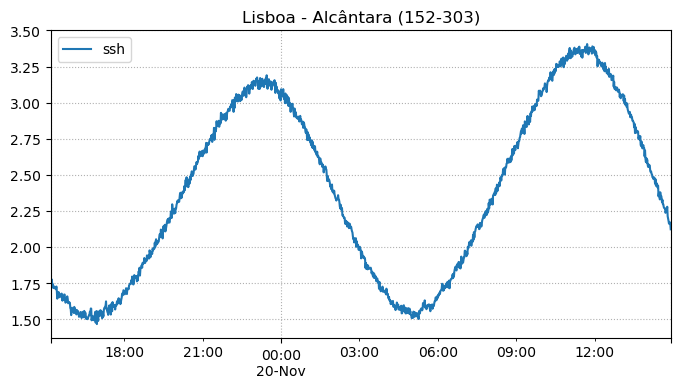

In [6]:
ax = ssh.plot(title=f"{station_name} ({station_id})", figsize=(8, 4), marker="")
ax.grid(ls=":")